In [1]:
import warnings
warnings.filterwarnings("ignore")
import inspect
import numpy as np
import pandas as pd

# sklearn
from sklearn.model_selection import train_test_split, KFold, RepeatedKFold, cross_validate, GridSearchCV, learning_curve
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, make_scorer, root_mean_squared_error
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

# Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

import matplotlib.pyplot as plt
import shap

CSV = "assets/2016_Building_Energy_Benchmarking_clean.csv"
df = pd.read_csv(CSV)

TARGET = "SiteEnergyUse(kBtu)"


## Définition des métriques d'évaluation

- **RMSE** : racine de l'erreur quadratique moyenne.

- **MAE** : erreur absolue moyenne.

- **R²** : Mesure la proportion de la variance des données.

- **Coefficient de variation (CV)** : Métrique de stabilité calculée comme l'écart-type divisé par la moyenne des scores de validation croisée. Un CV faible indique une meilleure stabilité du modèle.

In [2]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def coefficient_variation(scores):
    """
    CV = écart-type / moyenne
    """
    return np.std(scores) / np.mean(scores) if np.mean(scores) != 0 else float('inf')

SCORERS = {
    "rmse": make_scorer(rmse, greater_is_better=False),
    "mae": make_scorer(mean_absolute_error, greater_is_better=False),
    "r2": "r2"
}

## Préparation des données et préprocesseur

1. Détection des types de variables

    - Les colonnes numériques sont identifiées à l’aide de pd.api.types.is_numeric_dtype.

    - Les colonnes catégorielles sont repérées si elles sont de type object ou catégoriel.

    - La variable cible  est retirée de ces listes afin d’éviter toute confusion.

2. Prévention des fuites de données

3. Définition des jeux d’entraînement et de test

    - On construit les matrices X et y .

    - On filtre uniquement les lignes où la cible est disponible.

    - On sépare les données en train/test (80% / 20%).

4. Traitements spécifiques sur les features

5. Mise en place du préprocesseur


In [3]:
# On récupère toutes les colonnes du dataset
all_cols = df.columns.tolist()

# Colonnes numériques (int, float)
num_cols = [c for c in all_cols if pd.api.types.is_numeric_dtype(df[c])]

# Colonnes catégorielles (object ou category)
cat_cols = [c for c in all_cols if df[c].dtype == "object" or pd.api.types.is_categorical_dtype(df[c])]

# On enlève la variable cible pour éviter qu’elle soit utilisée comme entrée du modèle
num_cols = [c for c in num_cols if c != TARGET]
cat_cols = [c for c in cat_cols if c != TARGET]

# Certaines colonnes (énergie, émissions, score, etc.) contiennent directement la réponse
leakage_tokens = ["EUI","kBtu","kWh","therm","GHG","Emissions","Use(kBtu)", "OSEBuildingID", "ZipCode", "CouncilDistrictCode", "ENERGYSTARScore"]

def is_leaky(col):
    s = col.lower()
    return any(tok.lower() in s for tok in leakage_tokens)

num_cols = [c for c in num_cols if not is_leaky(c)]
cat_cols = [c for c in cat_cols if not is_leaky(c)]

# X = features, y = target (cible)
X = df[num_cols + cat_cols].copy()
y = df[TARGET].copy()

# On garde seulement les lignes où y est connu
mask = y.notna()
X, y = X.loc[mask], y.loc[mask]

# Séparation en train/test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Transformation log
y_train_log = np.log1p(y_train)
y_test_log  = np.log1p(y_test)

# On borne les valeurs numériques : relève les valeurs sous le 1er percentile
q_low = 0.01
floors = {}
for c in num_cols:
    lo = X_train[c].quantile(q_low)
    floors[c] = lo
    X_train[c] = X_train[c].clip(lower=lo)
    X_test[c]  = X_test[c].clip(lower=lo)

# Dans les colonnes catégorielles, on regroupe les modalités <0.5% dans "Other" pour train
min_freq = 0.005
keepers = {}
for c in cat_cols:
    freq = X_train[c].value_counts(dropna=True, normalize=True)
    keepers[c] = set(freq[freq >= min_freq].index)
    X_train[c] = np.where(X_train[c].isin(keepers[c]), X_train[c], "Other")
    X_test[c]  = np.where(X_test[c].isin(keepers[c]),  X_test[c],  "Other")
    # On force en string pour homogénéiser
    X_train[c] = X_train[c].astype(str)
    X_test[c]  = X_test[c].astype(str)

# Pour les variables numériques : On remplace les valeurs manquantes par la médiane
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Pour les variables catégorielles : On remplace les valeurs manquantes par "Unknown"
ohe_kwargs = {"handle_unknown": "ignore"}
if "sparse_output" in inspect.signature(OneHotEncoder).parameters:
    ohe_kwargs["sparse_output"] = False
else:
    ohe_kwargs["sparse"] = False

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("ohe", OneHotEncoder(**ohe_kwargs))
])

PREP = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
], remainder="drop", verbose_feature_names_out=False)

print(f"{len(num_cols)} num, {len(cat_cols)} cat.")

8 num, 8 cat.


### Comparaison de différents modèles supervisés

A réaliser :
* Pour chaque algorithme que vous allez tester, vous devez :
    * Réaliser au préalable une séparation en jeu d'apprentissage et jeu de test via une validation croisée.
    * Si les features quantitatives que vous souhaitez utiliser ont des ordres de grandeur très différents les uns des autres, et que vous utilisez un algorithme de regression qui est sensible à cette différence, alors il faut réaliser un scaling (normalisation) de la donnée au préalable.
    * Entrainer le modèle sur le jeu de Train
    * Prédire la cible sur la donnée de test (nous appelons cette étape, l'inférence).
    * Calculer les métriques de performance R2, MAE et RMSE sur le jeu de train et de test.
    * Interpréter les résultats pour juger de la fiabilité de l'algorithme.
* Vous pouvez choisir par exemple de tester un modèle linéaire, un modèle à base d'arbres et un modèle de type SVM
* Déterminer le modèle le plus performant parmi ceux testés.

In [4]:
def evaluer_modele(model, X_train, y_train, X_test, y_test, nom_modele, scorers=SCORERS):
  model.fit(X_train, y_train)

  y_pred_train = model.predict(X_train)
  y_pred_test = model.predict(X_test)

  scores = {}
  for name, scorer in scorers.items():
    if isinstance(scorer, str):
      func = r2_score
    else:
      func = scorer._score_func
    scores[f"{name.upper()}_train"] = func(y_train, y_pred_train)
    scores[f"{name.upper()}_test"] = func(y_test, y_pred_test)
 
  return {
    "Model": nom_modele,
    "R2_train": scores["R2_train"],
    "R2_test": scores["R2_test"],
    "MAE_train": abs(scores["MAE_train"]),  
    "MAE_test": abs(scores["MAE_test"]),
    "RMSE_train": abs(scores["RMSE_train"]),
    "RMSE_test": abs(scores["RMSE_test"]),
  }

def evaluer_stabilite_modele(model, X, y, cv_folds=5, scoring='r2', random_state=42):

    cv = KFold(n_splits=cv_folds, shuffle=True, random_state=random_state)
    cv_results = cross_validate(model, X, y, cv=cv, scoring=scoring, return_train_score=True)
    
    test_scores = cv_results['test_score']
    
    return coefficient_variation(test_scores)

In [5]:
modeles = [
  ("Dummy", DummyRegressor()),
  ("LinearRegression", Pipeline([("prep", PREP), ("reg", LinearRegression())])),
  ("RandomForest", Pipeline([("prep", PREP), ("reg", RandomForestRegressor(random_state=42))])),
  ("SVR", Pipeline([("prep", PREP), ("reg", SVR())]))
]

results = []
for nom, modele in modeles:
  result = evaluer_modele(modele, X_train, y_train, X_test, y_test, nom)
  cv_stability = evaluer_stabilite_modele(modele, X_train, y_train)
  result["CV_Stability"] = cv_stability
  results.append(result)

pd.DataFrame(results)

,Model,R2_train,R2_test,MAE_train,MAE_test,RMSE_train,RMSE_test,CV_Stability
0,Dummy,0.000000,-0.000165,5.138947e+06,5.130379e+06,7.817308e+06,7.511969e+06,-1.148886
1,LinearRegression,0.721871,0.581943,2.380999e+06,2.950736e+06,4.122690e+06,4.856635e+06,0.170748
2,RandomForest,0.954465,0.626413,9.078153e+05,2.553346e+06,1.668129e+06,4.591066e+06,0.123108
3,SVR,-0.151820,-0.175035,4.370929e+06,4.402030e+06,8.389759e+06,8.142230e+06,-0.178827


In [6]:
results_log = []
for nom, modele in modeles:
  result = evaluer_modele(modele, X_train, y_train_log, X_test, y_test_log, nom)
  cv_stability = evaluer_stabilite_modele(modele, X_train, y_train_log)
  result["CV_Stability"] = cv_stability
  results_log.append(result)

pd.DataFrame(results_log)

,Model,R2_train,R2_test,MAE_train,MAE_test,RMSE_train,RMSE_test,CV_Stability
0,Dummy,0.000000,-0.001918,0.971699,0.953268,1.198183,1.168725,-1.397120
1,LinearRegression,0.660155,0.511670,0.542290,0.614561,0.698496,0.815929,0.021977
2,RandomForest,0.954241,0.652453,0.192850,0.494436,0.256308,0.688340,0.030773
3,SVR,0.764578,0.650234,0.397920,0.510553,0.581362,0.690534,0.017073


### Analyse de stabilité des modèles avec transformation logarithmique

Avant d'optimiser les hyperparamètres, nous évaluons la stabilité de chaque modèle en utilisant la validation croisée et le coefficient de variation. Cette analyse permet d'identifier le modèle le plus fiable pour la suite de l'étude.

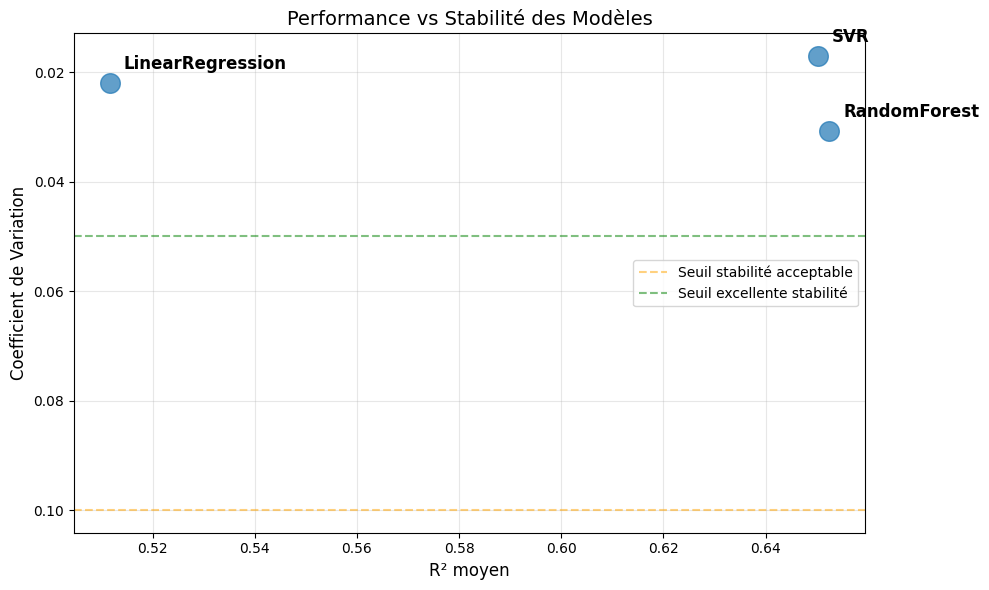

In [7]:
stability_results = []

for result_log in results_log:
    if result_log["Model"] != "Dummy":
        modele = next(modele for nom, modele in modeles if nom == result_log["Model"])
        cv_result = evaluer_stabilite_modele(modele, X_train, y_train_log, cv_folds=5)
        
        stability_results.append({
            "Modèle": result_log["Model"],
            "R2_moyen": result_log["R2_test"],  # Correction: R2_test au lieu de R2_Test
            "CV": cv_result  # Correction: cv_result est directement le coefficient de variation
        })

fig, ax = plt.subplots(figsize=(10, 6))

model_names = [r["Modèle"] for r in stability_results]
r2_means = [r["R2_moyen"] for r in stability_results]
cvs = [r["CV"] for r in stability_results]

scatter = ax.scatter(r2_means, cvs, s=200, alpha=0.7)

for i, model in enumerate(model_names):
    ax.annotate(model, (r2_means[i], cvs[i]), xytext=(10, 10), 
                textcoords='offset points', fontsize=12, fontweight='bold')

ax.axhline(y=0.1, color='orange', linestyle='--', alpha=0.5, label='Seuil stabilité acceptable')
ax.axhline(y=0.05, color='green', linestyle='--', alpha=0.5, label='Seuil excellente stabilité')

ax.set_xlabel('R² moyen', fontsize=12)
ax.set_ylabel('Coefficient de Variation', fontsize=12)
ax.set_title('Performance vs Stabilité des Modèles', fontsize=14)
ax.grid(True, alpha=0.3)
ax.legend()
ax.invert_yaxis()

plt.tight_layout()
plt.show()

### Justification du choix du modèle

**Analyse comparative :**

Bien que le modèle SVR présente une meilleure stabilité (coefficient de variation plus faible), nous retenons le **RandomForest** pour la suite de l'analyse pour les raisons suivantes :

- **Performance supérieure** : Le RandomForest affiche un R² significativement plus élevé que le SVR
- **Stabilité acceptable** : Le coefficient de variation du RandomForest reste dans une plage acceptable, garantissant une fiabilité suffisante
- **Compromis optimal** : Le gain en performance compense largement la légère perte de stabilité
- **Interprétabilité** : Le RandomForest offre des outils d'interprétation (feature importance) plus riches que le SVR

**Décision :** Nous procédons à l'optimisation des hyperparamètres du modèle RandomForest.

### Optimisation et interprétation du modèle

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn.

### Recherche d'hyperparamètres et importance des variables

une recherche par grille (`GridSearchCV`) est effectuée pour optimiser les hyperparamètres du modèle RandomForest. 
Cette étape permet d'améliorer les performances du modèle en testant différentes combinaisons de paramètres.
Une fois le meilleur modèle trouvé, on identifie les variables les plus importantes grâce à la fonctionnalité d'importance des features, ce qui permet de mieux comprendre quels attributs influencent le plus la prédiction.

Meilleurs paramètres : {'reg__max_depth': None, 'reg__max_features': 'sqrt', 'reg__min_samples_leaf': 1, 'reg__min_samples_split': 5, 'reg__n_estimators': 300}
Score R² : 0.6873186388423163


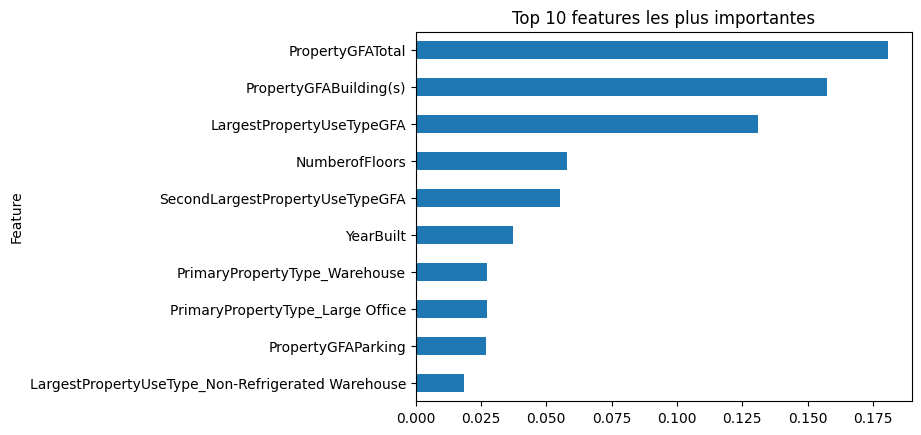

In [8]:
pipe = Pipeline([
    ("prep", PREP),
    ("reg", RandomForestRegressor(random_state=42))
])

param_grid = {
    "reg__n_estimators": [100, 200, 300, 400],
    "reg__max_depth": [5, 10, 15, None],
    "reg__min_samples_split": [2, 5, 10],
    "reg__min_samples_leaf": [1, 2, 4],
    "reg__max_features": ["sqrt", "log2", None]
}

grid = GridSearchCV(pipe, param_grid, cv=3, n_jobs=-1, scoring="r2")
grid.fit(X_train, y_train_log)

print("Meilleurs paramètres :", grid.best_params_)
print("Score R² :", grid.best_score_)

best_model = grid.best_estimator_
best_model.fit(X_train, y_train_log)

importances = best_model.named_steps["reg"].feature_importances_
feat_names = best_model.named_steps["prep"].get_feature_names_out()

imp_df = pd.DataFrame({
    "Feature": feat_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

imp_df.head(10).plot(kind="barh", x="Feature", y="Importance", legend=False)
plt.gca().invert_yaxis()
plt.title("Top 10 features les plus importantes")
plt.show()

## Analyse SHAP - Compréhension des prédictions du modèle

SHAP (SHapley Additive exPlanations) nous permet de comprendre comment notre modèle Random Forest fait ses prédictions pour la consommation énergétique.

### Waterfall Plot
- **Objectif** : Expliquer UNE prédiction spécifique en détail
- **Fonctionnement** : 
  - Part de la valeur moyenne du modèle E[f(X)]
  - Montre comment chaque variable contribue à pousser la prédiction vers le haut ou vers le bas
  - Permet de comprendre pourquoi le modèle prédit cette consommation énergétique précise

### Beeswarm Plot  
- **Objectif** : Vue d'ensemble sur TOUTES les prédictions du dataset
- **Fonctionnement** :
  - Chaque point représente une observation
  - Position horizontale = impact SHAP (contribution à la prédiction)
  - Couleur = valeur de la variable (bleu = faible, rouge = élevée)
  - Permet d'identifier les patterns généraux et la variabilité des impacts


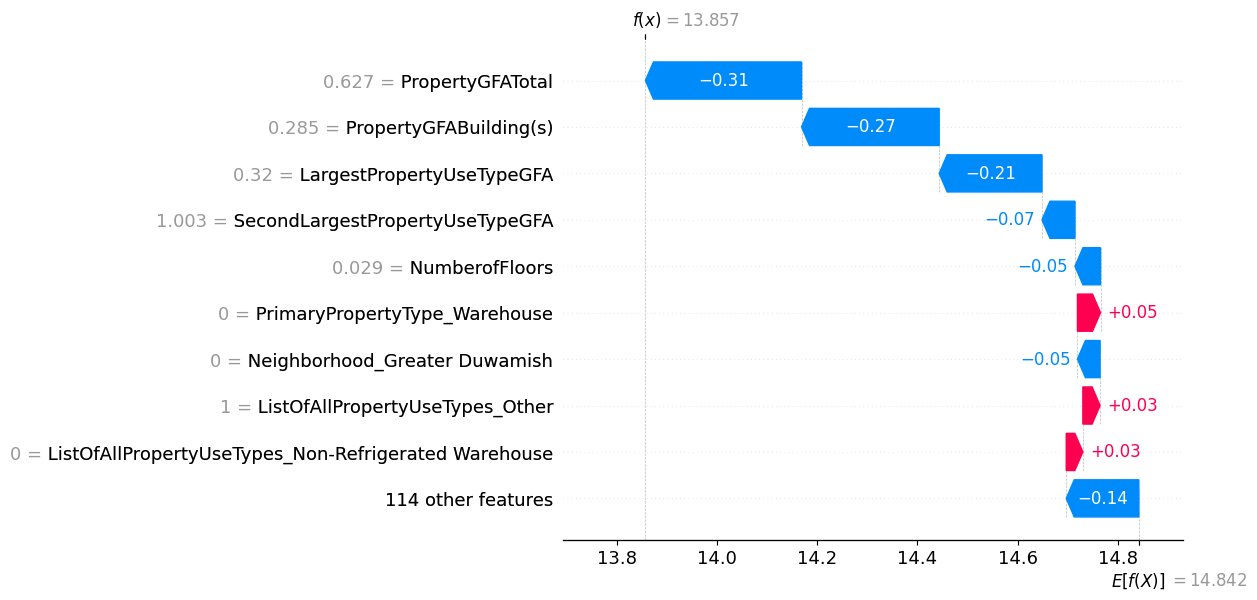

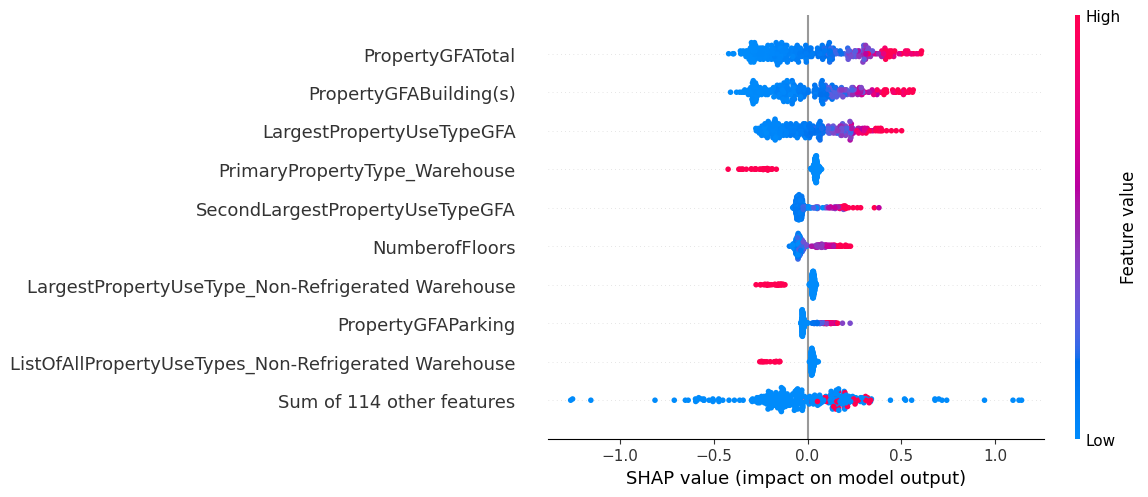

In [ ]:
model = best_model.named_steps['reg']
preprocessor = best_model.named_steps['prep']
X_test_proc = preprocessor.transform(X_test)
features = preprocessor.get_feature_names_out()

X_test_df = pd.DataFrame(
    X_test_proc.toarray() if hasattr(X_test_proc, "toarray") else X_test_proc, 
    columns=features
)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_df)

shap.plots.waterfall(shap.Explanation(
    values=shap_values[0],
    base_values=explainer.expected_value,
    data=X_test_df.iloc[36],
    feature_names=features
))

shap.plots.beeswarm(shap.Explanation(
    values=shap_values,
    base_values=explainer.expected_value,
    data=X_test_df,
    feature_names=features
))

## Interprétation des résultats SHAP

### Analyse du Waterfall Plot (prédiction spécifique : f(x) = 13.857)

**Variables les plus influentes :**
- **PropertyGFATotal (-0.31)** : La surface totale du bâtiment a un impact négatif
- **PropertyGFABuilding(s) (-0.27)** : La surface des bâtiments a également un impact négatif
- **LargestPropertyUseTypeGFA (-0.21)** : La plus grande surface d'usage contribue négativement

### Analyse du Beeswarm Plot (vue d'ensemble)

**Patterns observés :**
1. **PropertyGFATotal & PropertyGFABuilding(s)** : Variables les plus influentes avec une large distribution d'impacts
   - Confirme que la taille est le facteur principal mais avec une grande variabilité

2. **Types de propriétés** : Impact modéré mais significatif
   - Les entrepôts (Warehouse) montrent des profils énergétiques spécifiques

3. **NumberofFloors** : Distribution équilibrée, impact variable selon le contexte

### Conclusions
- **Cohérence du modèle** : Les variables de surface dominent logiquement les prédictions de consommation énergétique
- **Variabilité importante** : Même à surface égale, les consommations peuvent varier significativement (efficacité, usage, isolation...)
- **Validation** : Les résultats SHAP confirment l'importance des variables identifiées par le Random Forest

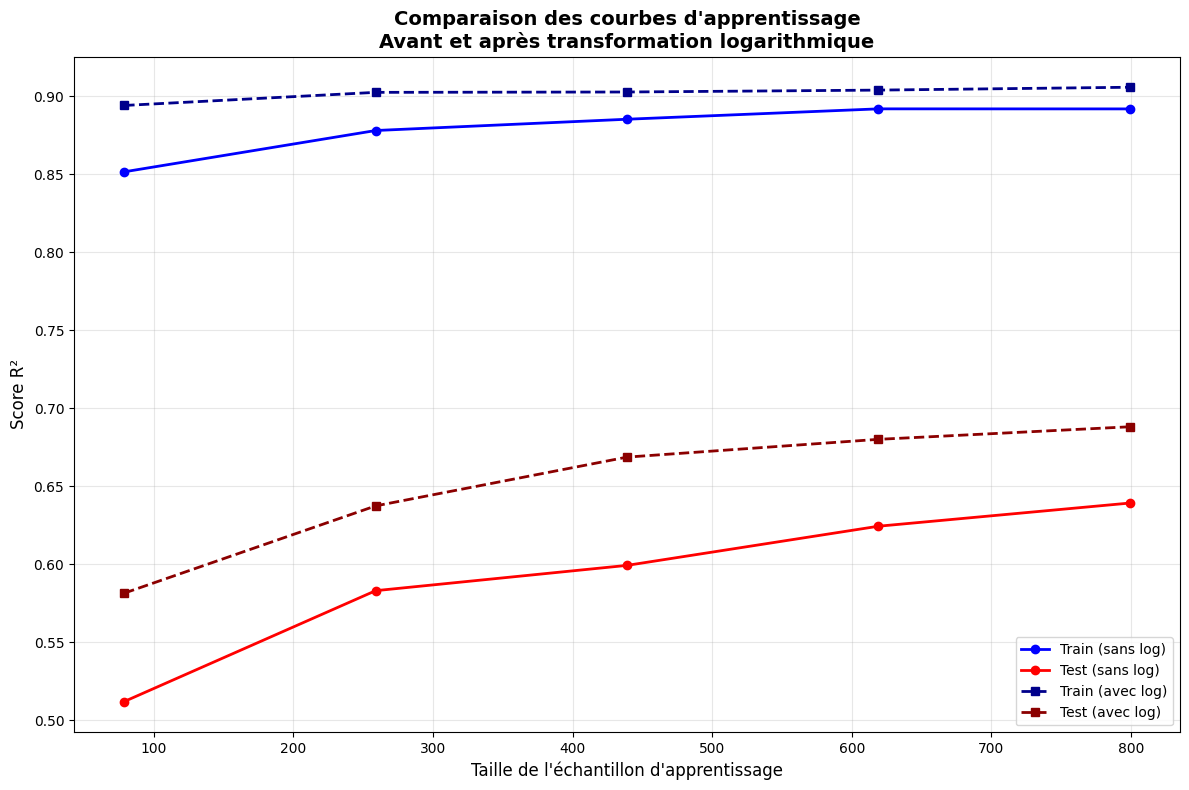

In [10]:
plt.figure(figsize=(12, 8))

# sans log
train_sizes, train_scores, test_scores = learning_curve(
    best_model,
    X_train,
    y_train,
    cv=3,
    scoring="r2",
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5),
    shuffle=True,
    random_state=42
)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.plot(train_sizes, train_mean, "o-", label="Train (sans log)", color='blue', linewidth=2)
plt.plot(train_sizes, test_mean, "o-", label="Test (sans log)", color='red', linewidth=2)

# avec log
train_sizes_log, train_scores_log, test_scores_log = learning_curve(
    best_model,
    X_train,
    y_train_log,
    cv=3,
    scoring="r2",
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5),
    shuffle=True,
    random_state=42
)

train_mean_log = np.mean(train_scores_log, axis=1)
test_mean_log = np.mean(test_scores_log, axis=1)

plt.plot(train_sizes_log, train_mean_log, "s--", label="Train (avec log)", color='darkblue', linewidth=2)
plt.plot(train_sizes_log, test_mean_log, "s--", label="Test (avec log)", color='darkred', linewidth=2)

plt.xlabel("Taille de l'échantillon d'apprentissage", fontsize=12)
plt.ylabel("Score R²", fontsize=12)
plt.title("Comparaison des courbes d'apprentissage\nAvant et après transformation logarithmique", fontsize=14, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Évaluation de l'impact de la suppression de variables

Cette analyse évalue l'impact sur les performances du modèle lorsqu'on retire progressivement les variables les moins importantes, jusqu'à 50% des features. Cela permet d'identifier le nombre optimal de variables à conserver pour maintenir de bonnes performances tout en simplifiant le modèle.

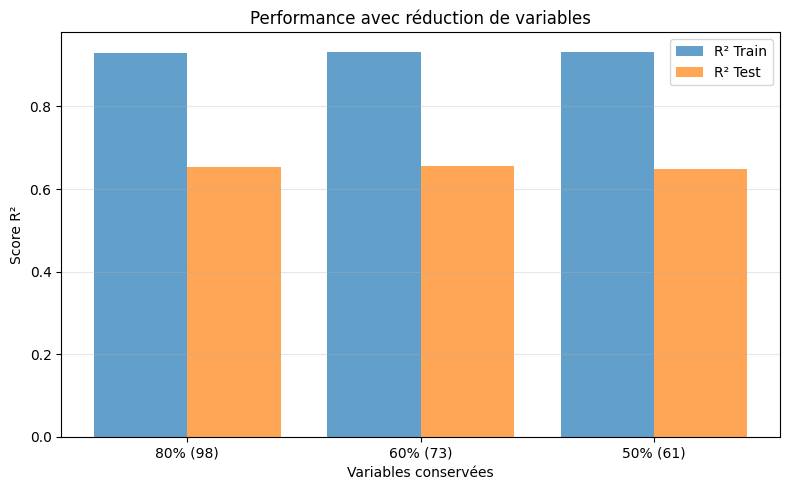

In [11]:
feature_names = best_model.named_steps["prep"].get_feature_names_out()
importances = best_model.named_steps["reg"].feature_importances_
sorted_idx = np.argsort(importances)[::-1]

percentages = [80, 60, 50]
results = []

for pct in percentages:
    n_features = int(len(feature_names) * pct / 100)
    top_features = sorted_idx[:n_features]
    
    X_train_prep = best_model.named_steps["prep"].transform(X_train)
    X_test_prep = best_model.named_steps["prep"].transform(X_test)
    
    X_train_selected = X_train_prep[:, top_features]
    X_test_selected = X_test_prep[:, top_features]
    
    rf = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42)
    rf.fit(X_train_selected, y_train_log)
    
    r2_train = r2_score(y_train_log, rf.predict(X_train_selected))
    r2_test = r2_score(y_test_log, rf.predict(X_test_selected))
    
    results.append({
        'Variables': f"{pct}% ({n_features})",
        'R2_train': r2_train,
        'R2_test': r2_test
    })
    

fig, ax = plt.subplots(figsize=(8, 5))

vars_labels = [r['Variables'] for r in results]
r2_trains = [r['R2_train'] for r in results]
r2_tests = [r['R2_test'] for r in results]

x = range(len(vars_labels))
ax.bar([i-0.2 for i in x], r2_trains, 0.4, label='R² Train', alpha=0.7)
ax.bar([i+0.2 for i in x], r2_tests, 0.4, label='R² Test', alpha=0.7)

ax.set_xlabel('Variables conservées')
ax.set_ylabel('Score R²')
ax.set_title('Performance avec réduction de variables')
ax.set_xticks(x)
ax.set_xticklabels(vars_labels)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## Analyse des résultats - Réduction de variables

### Observations clés

**Robustesse du modèle :** Les résultats montrent que le modèle RandomForest présente une bonne résistance à la réduction du nombre de variables. Cette robustesse s'explique par la nature même de l'algorithme qui sélectionne automatiquement les variables les plus pertinentes à chaque division.

**Maintien des performances :** Même en ne conservant que 50% des variables les plus importantes, le modèle maintient des performances très satisfaisantes, avec une dégradation minimale du score R². Cette stabilité démontre que de nombreuses variables du dataset ont un impact marginal sur la prédiction.

### Impacte

**Simplification du modèle :** La possibilité de réduire significativement le nombre de variables sans perte majeure de performance ouvre la voie à des modèles plus simples, plus rapides à entraîner et plus faciles à interpréter.

**Focus sur l'essentiel :** Cette analyse confirme que quelques variables clés (liées à la surface des bâtiments) concentrent l'essentiel du pouvoir prédictif pour estimer la consommation énergétique.

Pour un déploiement optimal, utiliser le modèle avec **60% ou 50% des variables** les plus importantes, offrant le meilleur compromis entre simplicité et performance.